# Fig 2 · Storage, search time and accuracy

* **A** storage of every index, with the folds whole → Spindle-naive and Spindle-naive → Spindle (above) and, on
  gene sets, Spindle-naive → Spindle (below).
* **B** end-to-end time per query (query logarithms + search, summed per query), whole tiles (whole-matrix scan,
  Spindle-naive, Spindle) and gene sets (Spindle-naive, Spindle-Partial). Each bar is split: the query logarithms
  (hatched, light, from the axis) and then the search (solid) up to the end-to-end time; error bars on the
  end-to-end time. The split point is the median of the query logarithms; the bar's end the median of the per-query
  totals (4 Nov: was search only).
* **C** accuracy of Spindle against the ranking of Spindle-naive at c = 5 % of N: RDE (CSV column `NX5`) and
  NNR(5 %, 5 % of N) (`overlap5`), whole tiles (g = 0.25) and gene sets (all gene-set sizes pooled).

Mean ± s.d. over seeds 0–4. Rows are shared by the three panels, divided by lines; left of A, each dataset's
cells, genes (p) and tiles. B's axis is a plain log scale (the squeezed 10–100 ms decade of the search-only version is gone). Speed-ups (search only and end to end) are given
in the text; build time, the cell ladder, RDE / NNR against |S| and the typical-query distances are appendix material
(`experiments/figures/_backup_2026-11-01/`).

**Run first:** `R0_index_cache` → `R1_index_cost` (`results/index_cost/builds.csv`), `R4_timing`
(`results/timing/whole_tile.csv`, `gene_set.csv`), `R2_whole_tile` (`results/whole_tile/nx.csv`) and `R3_gene_set`
(`results/gene_set/nx.csv`).
Writes `figures/fig2_cost/panels/{A,B,C,legend}.{pdf,png}` and `figures/fig2_cost/fig2_cost.{pdf,png}`.

In [1]:
import math
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.transforms import blended_transform_factory

import gene_set_accuracy as gsa
import style as ps
import whole_tile as wt

FIG = "fig2_cost"
RES = ROOT / "results" / "index_cost"
ORDER = ps.DATASET_ORDER
TC = ps.TIER_COLORS
WHOLE, NAIVE, SPINDLE, SPINDLE_GS = TC["whole"], TC["naive"], TC["spindle"], TC["spindle_partial"]
G = 0.25

b = pd.read_csv(RES / "builds.csv")
b["key"] = pd.Categorical(b["key"], ORDER, ordered=True)
b = b.sort_values(["key", "seed"])
_, t_whole = wt.timing_tables(pd.read_csv(ROOT / "results" / "timing" / "whole_tile.csv"))
t_whole = t_whole.set_index("key")
_, _, t_gene = gsa.timing_tables(pd.read_csv(ROOT / "results" / "timing" / "gene_set.csv"))
t_gene = t_gene.set_index("key")
whole = pd.read_csv(ROOT / "results" / "whole_tile" / "nx.csv")
whole = whole[whole.g == G].set_index("key")
gene = pd.read_csv(ROOT / "results" / "gene_set" / "nx.csv")
gene = gene[(gene.method == "spindle_partial") & (gene["size"] == 0)].set_index("key")
counts = b.groupby("key", observed=True)[["n_cells", "p", "n_tiles"]].first()
print(sorted(set(b.tag) | set(whole.tag) | set(gene.tag)))

# one row (mm): the three panels share the height and vertical margins, so the dataset rows line up
H, TOP, BOTTOM = 90.0, 6.0, 11.0
LEG_H = 7.0
ROW_UP, ROW_LO = -0.12, 0.12  # the two rows of a dataset (A, C); A's folds above and below them
STORAGE_XLIM = (0.7, 8000.0)  # MB
W_A, W_B, W_C = 88.0, 40.0, 52.0
LABEL_W = 47.0  # the dataset table left of A
TABLE = [("Cells", "n_cells", lambda v: f"{v / 1e3:,.0f}k", 28.0), ("Genes", "p", lambda v: f"{v:,}", 36.0),
         ("Tiles", "n_tiles", lambda v: f"{v:,}", 44.0)]  # header, column, format, right edge (mm)
SEP = dict(color="#BDBDBD", lw=0.4)


def box(fig, x, y, w, h):
    """Axes occupying the w x h mm box at (x, y) mm from the panel's top-left corner."""
    W, H_ = ps.size_mm(fig)
    return ps.axes(fig, left=x, top=y, right=W - x - w, bottom=H_ - y - h)


def rows(ax):
    n = len(ORDER)
    ax.set_ylim(n - 0.5, -0.5)
    ax.set_yticks(range(n))
    return n


def mean_sd(col):
    g = b.groupby("key", observed=True)[col]
    return g.mean().to_numpy(), g.std().to_numpy()


def marker(ax, x, y, tier, mk, filled=True, xerr=None, ms=3.2):
    k = TC[tier]
    ax.errorbar(x, y, xerr=xerr, fmt=mk, ms=ms, color=k, mfc=k if filled else "white", mec=k, mew=0.8,
                elinewidth=0.6, zorder=3)


def row_axis(ax):
    ax.set_yticklabels([])
    ax.tick_params(axis="y", length=0)


def separators(fig, x0=0.0, x1=None):
    """Lines between the dataset rows from x0 to x1 mm of the panel (the same heights in every panel, so they join
    up)."""
    W, H_ = ps.size_mm(fig)
    x1 = W if x1 is None else x1
    n = len(ORDER)
    for i in range(1, n):
        y = 1 - (TOP + i / n * (H_ - TOP - BOTTOM)) / H_
        fig.add_artist(Line2D([x0 / W, x1 / W], [y, y], transform=fig.transSubfigure, **SEP))

['method-v2']


## A · Storage (fold labels: whole → Spindle-naive, Spindle-naive → Spindle, and on gene sets Spindle-naive → Spindle, of the means over seeds)

figures/fig2_cost/panels/A.pdf/.png: 88 x 90 mm, 0.0 / 0.6 MB


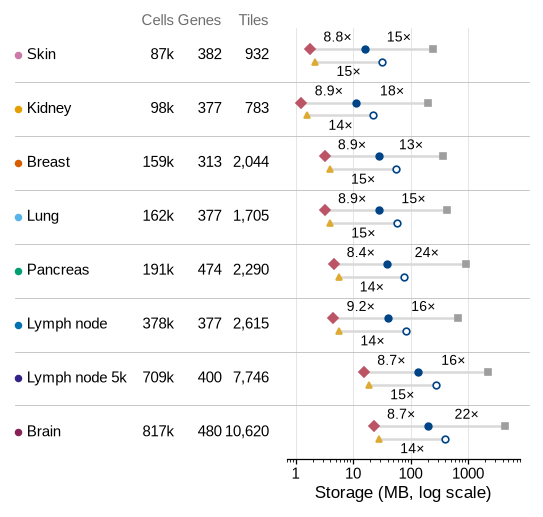

In [2]:
def fold_label(f):
    return f"{f:.0f}×" if f >= 10 else f"{f:.1f}×"


def panel_a(fig):
    ax = box(fig, LABEL_W, TOP, W_A - LABEL_W - 1.5, H - TOP - BOTTOM)
    n = rows(ax)
    y = np.arange(n)
    up, lo = y + ROW_UP, y + ROW_LO
    mb = {c: tuple(v / 1e6 for v in mean_sd(f"bytes_{c}"))
          for c in ("whole", "naive", "spindle", "naive_partial", "spindle_partial")}
    for yy, a, c in ((up, "whole", "spindle"), (lo, "naive_partial", "spindle_partial")):
        ax.hlines(yy, mb[c][0], mb[a][0], color=ps.LIGHT, lw=1.2, zorder=1)
    for c, yy, tier, mk, filled in (("whole", up, "whole", "s", True), ("naive", up, "naive", "o", True),
                                    ("spindle", up, "spindle", "D", True), ("naive_partial", lo, "naive", "o", False),
                                    ("spindle_partial", lo, "spindle_partial", "^", True)):
        marker(ax, mb[c][0], yy, tier, mk, filled, xerr=mb[c][1])
    for i in range(n):  # folds at the log midpoints, above the whole-tile row and below the gene-set row
        for a, c, yy, va in (("naive", "whole", up[i] - 0.08, "bottom"), ("spindle", "naive", up[i] - 0.08, "bottom"),
                             ("spindle_partial", "naive_partial", lo[i] + 0.08, "top")):
            xm = math.sqrt(mb[a][0][i] * mb[c][0][i])
            ax.text(xm, yy, fold_label(mb[c][0][i] / mb[a][0][i]), ha="center", va=va, fontsize=6.5)
    ax.set_xscale("log")
    ps.plain_log(ax, "x", subs=(1.0,))
    ps.log_grid(ax, "x")
    ax.set_xlim(*STORAGE_XLIM)
    ax.set_xlabel("Storage (MB, log scale)")
    row_axis(ax)
    ax.spines["left"].set_visible(False)
    W, _ = ps.size_mm(fig)
    tr = blended_transform_factory(fig.transSubfigure, ax.transData)  # x in panel fractions, y in rows
    for i, k in enumerate(ORDER):  # the dataset's colour, as in every other figure, then its size
        ax.plot(1.5 / W, i, "o", ms=2.6, color=ps.DATASET_COLORS[k], clip_on=False, transform=tr)
        ax.text(3.0 / W, i, ps.DATASET_LABELS[k], ha="left", va="center", fontsize=ps.TICK_PT, transform=tr)
        for _, col, fmt, x in TABLE:
            ax.text(x / W, i, fmt(int(counts.loc[k, col])), ha="right", va="center", fontsize=ps.TICK_PT,
                    transform=tr)
    for head, _, _, x in TABLE:
        ax.text(x / W, -0.5, head, ha="right", va="bottom", fontsize=ps.TICK_PT, color=ps.MUTED, transform=tr)
    separators(fig, x0=1.5 - 0.5)  # from the colour dots


fig = ps.panel(W_A, H); panel_a(fig); ps.save_panel(fig, FIG, "A")

## B · End-to-end time per query (query logarithms, then search), whole tiles and gene sets

figures/fig2_cost/panels/B.pdf/.png: 40 x 90 mm, 0.0 / 0.1 MB


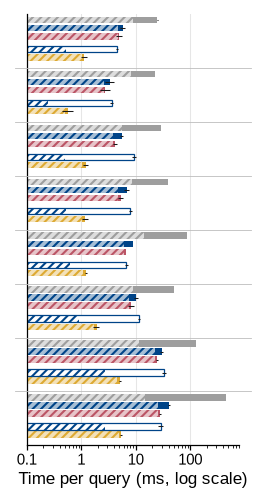

In [3]:
BH = 0.15  # bar height; the gene-set pair sits below the whole-tile three after a gap
# (offset, table, query-logarithm column, end-to-end column, colour, filled)
BARS = [(-2.6 * BH, t_whole, "qlog_whole_ms", "e2e_whole_ms", WHOLE, True),
        (-1.6 * BH, t_whole, "qlog_block_ms", "e2e_naive_ms", NAIVE, True),
        (-0.6 * BH, t_whole, "qlog_block_ms", "e2e_spindle_ms", SPINDLE, True),
        (1.0 * BH, t_gene, "qlog_naive_partial_ms", "naive_partial_ms", NAIVE, False),  # outlined, as A's hollow marker
        (2.0 * BH, t_gene, "qlog_spindle_partial_ms", "e2e_spindle_partial_ms", SPINDLE_GS, True)]
HATCH = "//////"
TINT = 0.35  # the query-logarithm segment: the method's colour mixed with white


def tint(c, f=TINT):
    from matplotlib.colors import to_rgb
    return tuple(f * x + (1 - f) for x in to_rgb(c))


B_XLIM = (0.1, 800.0)  # plain log axis (4 Nov: end-to-end 0.6-460 ms, query logarithms from 0.25 ms; no squeezed decade)


def panel_b(fig):
    W, _ = ps.size_mm(fig)
    ax = box(fig, 2.0, TOP, W - 4.0, H - TOP - BOTTOM)
    ax.set_xscale("log")
    for i, k in enumerate(ORDER):
        for off, t, qcol, col, c, filled in BARS:
            r = t.loc[k]
            q, e = r[qcol], r[col]
            ax.barh(i + off, q - B_XLIM[0], left=B_XLIM[0], height=BH * 0.8, color=tint(c) if filled else "white",
                    ec=c, lw=0, hatch=HATCH, zorder=2)  # query logarithms
            ax.barh(i + off, e - q, left=q, height=BH * 0.8, color=c if filled else "white", ec=c, lw=0, zorder=2)
            if not filled:  # one outline round both segments
                ax.barh(i + off, e - B_XLIM[0], left=B_XLIM[0], height=BH * 0.8, fc="none", ec=c, lw=0.6, zorder=2.2)
            ax.errorbar(e, i + off, xerr=r[f"{col}_sd"], fmt="none", ecolor=ps.INK, elinewidth=0.5, zorder=3)
    rows(ax)
    row_axis(ax)
    ax.set_xlim(*B_XLIM)
    ps.plain_log(ax, "x", subs=(1.0,))
    ps.log_grid(ax, "x")
    ax.set_xlabel("Time per query (ms, log scale)")
    separators(fig)


fig = ps.panel(W_B, H); panel_b(fig); ps.save_panel(fig, FIG, "B")


## C · Accuracy of Spindle: RDE and NNR, whole tiles and gene sets

figures/fig2_cost/panels/C.pdf/.png: 52 x 90 mm, 0.0 / 0.1 MB


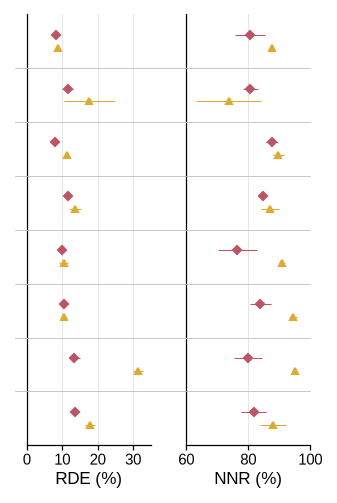

In [4]:
def panel_c(fig):
    W, _ = ps.size_mm(fig)
    left, right = 2.0, 2.0
    w = (W - left - right) / 2
    for j, (col, xlabel, xlim, ticks) in enumerate((("NX5", "RDE (%)", (0, 35), (0, 10, 20, 30)),
                                                     ("overlap5", "NNR (%)", (60, 100), (60, 80, 100)))):
        ax = box(fig, left + j * w + (3.0 if j else 0.0), TOP, w - 3.0, H - TOP - BOTTOM)
        for t, dy, c, mk in ((whole, ROW_UP, SPINDLE, "D"), (gene, ROW_LO, SPINDLE_GS, "^")):
            for i, k in enumerate(ORDER):
                r = t.loc[k]
                ax.errorbar(100 * r[col], i + dy, xerr=100 * r[f"{col}_sd"], fmt=mk, ms=2.8, color=c,
                            elinewidth=0.5, zorder=3)
        rows(ax)
        row_axis(ax)
        ax.set_xlim(*xlim)
        ax.set_xticks(ticks)
        ax.grid(True, axis="x", color="#E6E6E6", linewidth=0.5, zorder=0)
        ax.set_axisbelow(True)
        ax.set_xlabel(xlabel)
    separators(fig, x1=W - right)  # to NNR's 100 line


fig = ps.panel(W_C, H); panel_c(fig); ps.save_panel(fig, FIG, "C")

## Legend and full figure

figures/fig2_cost/panels/legend.pdf/.png: 180 x 7 mm, 0.0 / 0.1 MB
figures/fig2_cost/fig2_cost.pdf/.png: 180 x 97 mm, 0.0 / 1.1 MB


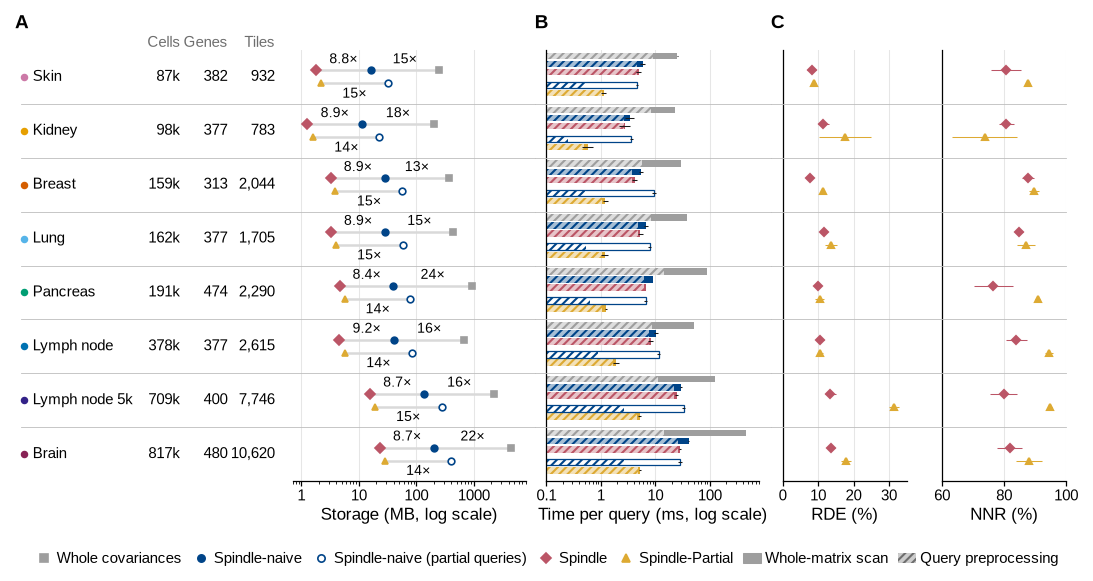

<Figure size 1062.99x41.3386 with 0 Axes>

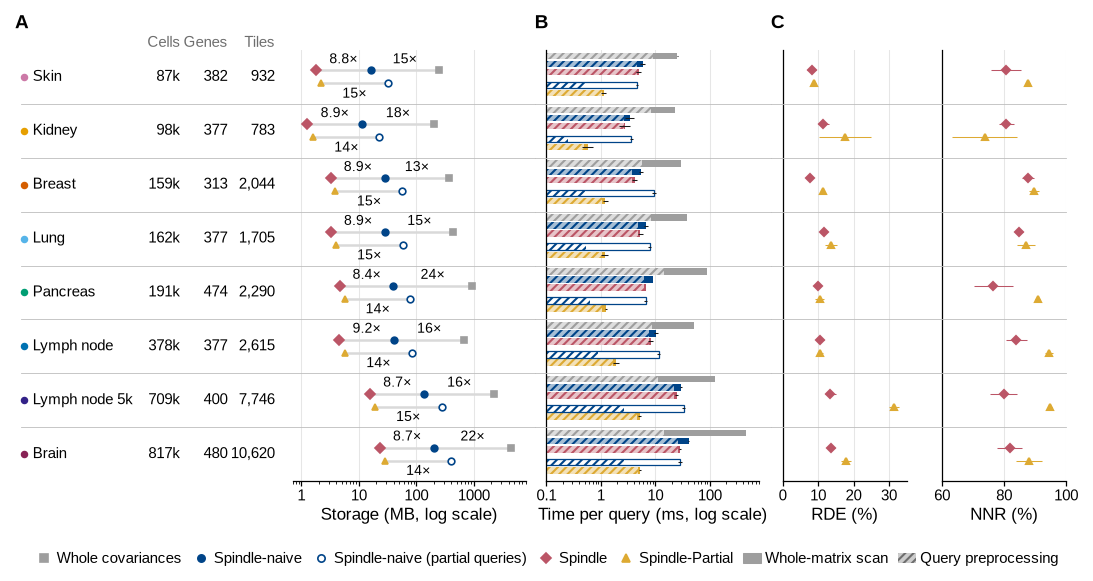

In [5]:
def legend(fig):
    def h(tier, mk, label, filled=True):
        k = TC[tier]
        return Line2D([], [], ls="", marker=mk, ms=3.5, color=k, mfc=k if filled else "white", mec=k, mew=0.8,
                      label=label)

    handles = [h("whole", "s", "Whole covariances"), h("naive", "o", "Spindle-naive"),
               h("naive", "o", "Spindle-naive (partial queries)", filled=False),
               h("spindle", "D", "Spindle"), h("spindle_partial", "^", "Spindle-Partial"),
               Patch(color=WHOLE, label="Whole-matrix scan"),
               Patch(fc=tint(ps.MUTED), ec=ps.MUTED, lw=0, hatch=HATCH, label="Query preprocessing")]
    fig.legend(handles=handles, ncol=7, loc="upper center", columnspacing=0.7, handletextpad=0.3)


fig = ps.panel(180, LEG_H); legend(fig); ps.save_panel(fig, FIG, "legend")

page = ps.page(180, H + LEG_H)
panel_a(ps.place(page, "A", 0, 0, W_A, H))
panel_b(ps.place(page, "B", W_A, 0, W_B, H))
panel_c(ps.place(page, "C", W_A + W_B, 0, W_C, H))
legend(ps.place(page, None, 0, H + 1.0, 180, LEG_H - 1.0))
ps.save_figure(page, FIG)
page